# Experiments 010 to 012: 1.5B mirror analysis plots

This notebook analyses the completed 1.5B mirror. Experiment 010 is the base-start MC-SFT exposure sweep, experiment 011 is MC-SFT after the exact 009 seed-0 GSM8K-SFT adapter, and experiment 012 is GRPO directly from the pretrained base.

The main comparisons are cross-referenced with experiments 007, 008 and 009. All tier values are recalculated from per-item predictions with the validated tier grouping. Experiment 010 has three probe seeds at every exposure, seed 0 generation at 2 and 32 passes, and three generative seeds at 8 passes. Experiment 011 has three full evaluations. Experiment 012 and the paired method contrasts are seed 0.

These are method-as-practised comparisons. MC-SFT and GRPO use different objectives, learning rates, schedules, KL treatment and compute. Experiment 012 is a prospectively recorded extension of the frozen protocol, not part of the original proposal's 3B-only base-GRPO cell.

Figures are saved to analysis/figures/010_012_1 as 300 dpi PNG files.

In [1]:
# load the complete 1.5B mirror and the matched earlier references
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'config.py').exists():
    raise FileNotFoundError('repository root containing config.py was not found')
sys.path.insert(0, str(ROOT))

from analysis.plotting import heatmap_text_color
from analysis.stats import align_pred_rows, holm, mcnemar_exact
from data.subjects import TIERS as VALIDATED_TIERS

RES = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '010_012_1'
FIG.mkdir(parents=True, exist_ok=True)

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {
    'base': '#4C78A8', 'gsm_sft': '#9D755D',
    'base_grpo': '#F58518', 'warm_grpo': '#E45756',
    'base_mc': '#54A24B', 'warm_mc': '#B279A2',
    'p2': '#72B7B2', 'p8': '#54A24B', 'p32': '#B279A2',
}
TIER_COLORS = {'easy': '#59A14F', 'medium': '#F28E2B', 'hard': '#E15759', 'overall': '#4C78A8'}
EXPOSURES = ['p2', 'p8', 'p32']
PASSES = {'p2': 2, 'p8': 8, 'p32': 32}
STEPS = {'p2': 31, 'p8': 123, 'p32': 490}
SEEDS = [0, 1, 2]
GROUPS = ['easy', 'medium', 'hard', 'overall']
TIER_LOOKUP = {subject: tier for tier, subjects in VALIDATED_TIERS.items() for subject in subjects}
SUBJECTS = [subject for tier in ['easy', 'medium', 'hard'] for subject in VALIDATED_TIERS[tier]]
SHORT_SUBJECTS = [subject.replace('high_school_', 'hs_') for subject in SUBJECTS]

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def retag(rows):
    order = {subject: index for index, subject in enumerate(SUBJECTS)}
    tagged = [{**row, 'tier': TIER_LOOKUP[row['subject']]} for row in rows]
    return sorted(tagged, key=lambda row: order[row['subject']])

def accuracy(rows, group='overall'):
    selected = rows if group == 'overall' else [row for row in rows if row['tier'] == group]
    return float(np.mean([bool(row['correct']) for row in selected]))

def subject_accuracy(rows):
    return {subject: accuracy([row for row in rows if row['subject'] == subject]) for subject in SUBJECTS}

def diagnosis(rows):
    return {
        'format compliance': float(np.mean([bool(row['format_ok']) for row in rows])),
        'extraction failure': float(np.mean([row['pred'] is None for row in rows])),
        'mean response length': float(np.mean([row['n_tokens'] for row in rows])),
    }

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')
    print('saved', name)

def signature(rows):
    return [(row['subject'], row['gold'], row['pred'], bool(row['correct'])) for row in rows]

RUN10 = {}
for exposure in EXPOSURES:
    RUN10[exposure] = {}
    for seed in SEEDS:
        folder = RES / f'010_{exposure}_COLAB_FULL_B15_sft_only_seed{seed}'
        item = {
            'folder': folder, 'manifest': jload(folder / 'manifest.json'),
            'summary': jload(folder / 'summary.json'), 'trainlog': jload(folder / 'sft_trainlog.json'),
            'probe': retag(jsonl(folder / 'sft_logprob_preds.jsonl')),
        }
        if (folder / 'sft_preds.jsonl').exists():
            item['gen'] = retag(jsonl(folder / 'sft_preds.jsonl'))
            item['eval'] = jload(folder / 'sft_eval.json')
            item['eval_manifest'] = jload(folder / 'sft_eval_manifest.json')
        RUN10[exposure][seed] = item

RUN11 = {}
for seed in SEEDS:
    folder = RES / f'011_wsft_COLAB_FULL_B15_sft_only_seed{seed}'
    RUN11[seed] = {
        'folder': folder, 'manifest': jload(folder / 'manifest.json'),
        'summary': jload(folder / 'summary.json'), 'trainlog': jload(folder / 'sft_trainlog.json'),
        'probe': retag(jsonl(folder / 'sft_logprob_preds.jsonl')),
        'gen': retag(jsonl(folder / 'sft_preds.jsonl')), 'eval': jload(folder / 'sft_eval.json'),
        'eval_manifest': jload(folder / 'sft_eval_manifest.json'),
    }

D9 = {}
for seed in (0, 1):
    folder = RES / f'009_COLAB_FULL_B15_sft_grpo_seed{seed}'
    D9[seed] = {
        'folder': folder, 'manifest': jload(folder / 'manifest.json'),
        'trainlog': jload(folder / 'grpo_trainlog.json'),
        'sft_gen': retag(jsonl(folder / 'sft_preds.jsonl')),
        'sft_probe': retag(jsonl(folder / 'sft_logprob_preds.jsonl')),
        'grpo_gen': retag(jsonl(folder / 'grpo_preds.jsonl')),
        'grpo_probe': retag(jsonl(folder / 'grpo_logprob_preds.jsonl')),
    }

BASE_DIR = RES / 'base_evals' / '012_COLAB_FULL_B15'
BASE_GEN = retag(jsonl(BASE_DIR / 'base_preds.jsonl'))
BASE_PROBE = retag(jsonl(BASE_DIR / 'base_logprob_preds.jsonl'))
D12_DIR = RES / '012_COLAB_FULL_B15_base_grpo_seed0'
D12 = {
    'manifest': jload(D12_DIR / 'manifest.json'), 'summary': jload(D12_DIR / 'summary.json'),
    'trainlog': jload(D12_DIR / 'grpo_trainlog.json'),
    'gen': retag(jsonl(D12_DIR / 'grpo_preds.jsonl')),
    'probe': retag(jsonl(D12_DIR / 'grpo_logprob_preds.jsonl')),
    'eval': jload(D12_DIR / 'grpo_eval.json'),
}

BASE_GRPO_SPECS = {
    '0.5B': ('005_COLAB_FULL_B05_base_grpo_seed0', '005_COLAB_FULL_B05'),
    '1.5B': ('012_COLAB_FULL_B15_base_grpo_seed0', '012_COLAB_FULL_B15'),
    '3B': ('004_COLAB_FULL_B3_base_grpo_seed0', '004_COLAB_FULL_B3'),
}
BASE_GRPO = {}
for scale, (run_tag, base_tag) in BASE_GRPO_SPECS.items():
    run_dir = RES / run_tag
    base_dir = RES / 'base_evals' / base_tag
    BASE_GRPO[scale] = {
        'base': retag(jsonl(base_dir / 'base_preds.jsonl')),
        'base_probe': retag(jsonl(base_dir / 'base_logprob_preds.jsonl')),
        'grpo': retag(jsonl(run_dir / 'grpo_preds.jsonl')),
        'eval': jload(run_dir / 'grpo_eval.json'),
        'manifest': jload(run_dir / 'manifest.json'),
    }

## 1. Result completeness and protocol checks

The checks below stop the notebook before any plot if a planned seed, evaluation, training step or provenance field is missing. They also verify that the repeated base probes are identical.

In [2]:
# verify every expected artifact before calculating the comparisons
health_rows = []
devices = set()
commits = set()
base_signatures = []
for exposure in EXPOSURES:
    for seed in SEEDS:
        item = RUN10[exposure][seed]
        manifest = item['manifest']
        losses = [row for row in item['trainlog'] if 'loss' in row and 'step' in row]
        assert manifest['seed'] == seed and item['summary']['seed'] == seed
        assert manifest['config']['train']['max_steps'] == STEPS[exposure]
        assert manifest['config']['train']['sft_data'] == 'mmlu_mc'
        assert manifest['config']['train']['sft_val_examples'] == 0
        assert len(losses) == STEPS[exposure] and len(item['probe']) == 1884
        assert manifest['resolved_dtype'] == 'bfloat16' and manifest['git']['dirty'] is False
        assert 'out of memory' not in (item['folder'] / 'run.log').read_text().lower()
        devices.add(manifest['gpu']['device'])
        commits.add(manifest['git']['commit'])
        expected_gen = seed == 0 or exposure == 'p8'
        assert ('gen' in item) == expected_gen
        if expected_gen:
            assert len(item['gen']) == 1884 and item['eval_manifest']['completed'] is True
            assert item['eval_manifest']['seed_override'] == seed
        health_rows.append({
            'experiment': f'010 {exposure}', 'seed': seed, 'steps': STEPS[exposure],
            'probe items': len(item['probe']), 'generative items': len(item.get('gen', [])),
            'train minutes': manifest['timings_sec']['sft_train'] / 60,
        })
    base_rows = retag(jsonl(RES / 'base_evals' / f'010_{exposure}_COLAB_FULL_B15' / 'base_logprob_preds.jsonl'))
    base_signatures.append(signature(base_rows))

for seed in SEEDS:
    item = RUN11[seed]
    manifest = item['manifest']
    losses = [row for row in item['trainlog'] if 'loss' in row and 'step' in row]
    assert manifest['seed'] == seed and item['summary']['seed'] == seed
    assert manifest['config']['train']['max_steps'] == 123
    assert manifest['config']['train']['sft_data'] == 'mmlu_mc'
    assert manifest['config']['train']['sft_from_adapter'].endswith('009_COLAB_FULL_B15_sft_grpo_seed0/sft')
    assert len(losses) == 123 and len(item['probe']) == len(item['gen']) == 1884
    assert item['eval_manifest']['completed'] is True and item['eval_manifest']['seed_override'] == seed
    assert manifest['resolved_dtype'] == 'bfloat16' and manifest['git']['dirty'] is False
    assert 'out of memory' not in (item['folder'] / 'run.log').read_text().lower()
    devices.add(manifest['gpu']['device'])
    commits.add(manifest['git']['commit'])
    health_rows.append({
        'experiment': '011 warm p8', 'seed': seed, 'steps': 123,
        'probe items': len(item['probe']), 'generative items': len(item['gen']),
        'train minutes': manifest['timings_sec']['sft_train'] / 60,
    })
base_11 = retag(jsonl(RES / 'base_evals' / '011_wsft_COLAB_FULL_B15' / 'base_logprob_preds.jsonl'))
base_signatures.append(signature(base_11))
base_signatures.append(signature(BASE_PROBE))
assert all(item == base_signatures[0] for item in base_signatures[1:])

reward_rows_12 = [row for row in D12['trainlog'] if 'reward' in row and 'step' in row]
assert len(reward_rows_12) == 500
assert D12['manifest']['condition'] == 'BASE_GRPO' and D12['manifest']['seed'] == 0
assert D12['manifest']['config']['train']['max_steps'] == 500
assert D12['manifest']['config']['exec']['grpo_batch_size'] is None
assert D12['manifest']['config']['exec']['grpo_grad_accum'] == 1
assert D12['manifest']['resolved_dtype'] == 'bfloat16' and D12['manifest']['git']['dirty'] is False
assert len(D12['gen']) == len(D12['probe']) == 1884
assert 'out of memory' not in (D12_DIR / 'run.log').read_text().lower()
devices.add(D12['manifest']['gpu']['device'])
commits.add(D12['manifest']['git']['commit'])
health_rows.append({
    'experiment': '012 base GRPO', 'seed': 0, 'steps': 500,
    'probe items': len(D12['probe']), 'generative items': len(D12['gen']),
    'train minutes': D12['manifest']['timings_sec']['grpo_train'] / 60,
})

assert devices == {'NVIDIA A100-SXM4-80GB'}
assert len(commits) == 1
health_tbl = pd.DataFrame(health_rows)
display(health_tbl.set_index(['experiment', 'seed']).round(3))
print('training commit:', next(iter(commits))[:7])
print('gpu:', next(iter(devices)))
print('all repeated base probes are identical')
print('figures ->', FIG)

steps  probe items  generative items  train minutes
experiment    seed                                                     
010 p2        0        31         1884              1884          1.286
              1        31         1884                 0          1.427
              2        31         1884                 0          1.384
010 p8        0       123         1884              1884          2.797
              1       123         1884              1884          2.933
              2       123         1884              1884          2.961
010 p32       0       490         1884              1884          8.963
              1       490         1884                 0          9.025
              2       490         1884                 0          9.072
011 warm p8   0       123         1884              1884          3.143
              1       123         1884              1884          2.829
              2       123         1884              1884          2.825
012 base GRPO 0       500         1884              1884        302.313

training commit: 96ae500
gpu: NVIDIA A100-SXM4-80GB
all repeated base probes are identical
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/010_012_1


## 2. Experiment 010 exposure curve

The loss and probe curves use three seeds at every exposure. The complete generative exposure curve is seed 0, while the 8-pass point also shows its three-seed range.

saved fig01_mc_sft_loss


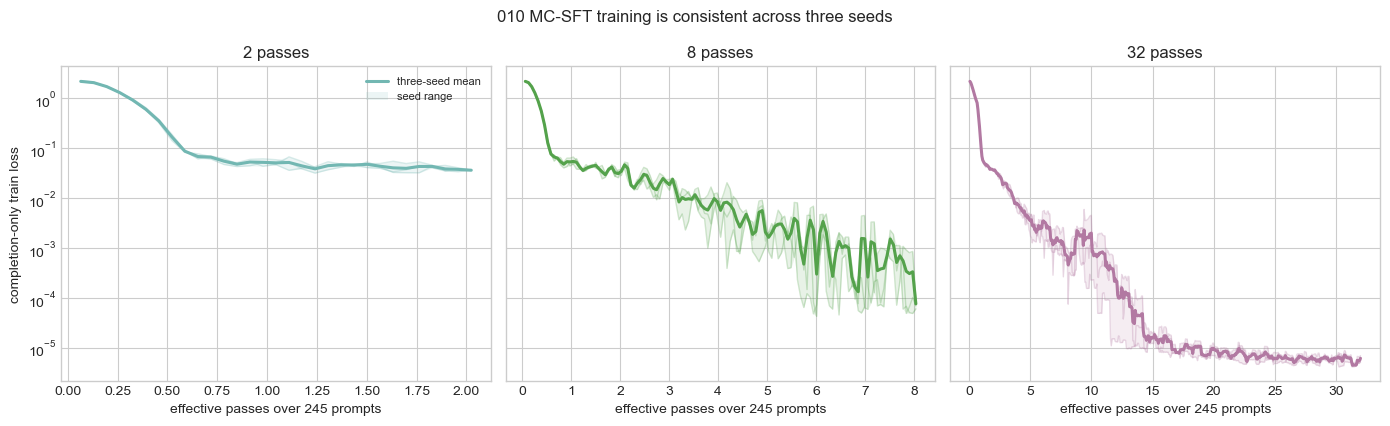

In [3]:
# plot the three-seed MC-SFT loss at every training budget
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
for ax, exposure in zip(axes, EXPOSURES):
    curves = []
    steps = None
    window = max(2, STEPS[exposure] // 45)
    for seed in SEEDS:
        rows = [row for row in RUN10[exposure][seed]['trainlog'] if 'loss' in row and 'step' in row]
        frame = pd.DataFrame(rows)
        steps = frame['step'].to_numpy()
        values = frame['loss'].rolling(window, min_periods=1).mean().to_numpy()
        curves.append(values)
        ax.plot(steps * 16 / 245, values, color=COLORS[exposure], alpha=0.28, lw=1)
    curves = np.vstack(curves)
    ax.plot(steps * 16 / 245, curves.mean(axis=0), color=COLORS[exposure], lw=2.2, label='three-seed mean')
    ax.fill_between(steps * 16 / 245, curves.min(axis=0), curves.max(axis=0),
                    color=COLORS[exposure], alpha=0.13, linewidth=0, label='seed range')
    ax.set_yscale('log')
    ax.set_title(f'{PASSES[exposure]} passes')
    ax.set_xlabel('effective passes over 245 prompts')
axes[0].set_ylabel('completion-only train loss')
axes[0].legend(fontsize=8)
fig.suptitle('010 MC-SFT training is consistent across three seeds')
fig.tight_layout()
save(fig, 'fig01_mc_sft_loss')
plt.show()

In [4]:
# calculate the probe and available generative endpoints by tier
probe_rows = []
gen_rows = []
for exposure in EXPOSURES:
    for seed in SEEDS:
        for group in GROUPS:
            probe_rows.append({
                'exposure': exposure, 'passes': PASSES[exposure], 'seed': seed,
                'group': group, 'accuracy': accuracy(RUN10[exposure][seed]['probe'], group),
            })
        if 'gen' in RUN10[exposure][seed]:
            for group in GROUPS:
                gen_rows.append({
                    'exposure': exposure, 'passes': PASSES[exposure], 'seed': seed,
                    'group': group, 'accuracy': accuracy(RUN10[exposure][seed]['gen'], group),
                })
probe_df = pd.DataFrame(probe_rows)
gen_df = pd.DataFrame(gen_rows)
probe_summary = probe_df.groupby(['exposure', 'passes', 'group'])['accuracy'].agg(['mean', 'std', 'min', 'max']).reset_index()
gen_summary = gen_df.groupby(['exposure', 'passes', 'group'])['accuracy'].agg(['mean', 'std', 'min', 'max', 'count']).reset_index()
display(probe_summary.set_index(['exposure', 'group']).round(4))
display(gen_summary.set_index(['exposure', 'group']).round(4))

passes    mean     std     min     max
exposure group                                          
p2       easy          2  0.8191  0.0011  0.8180  0.8203
         hard          2  0.4335  0.0186  0.4192  0.4545
         medium        2  0.7022  0.0034  0.6995  0.7061
         overall       2  0.7003  0.0046  0.6964  0.7054
p32      easy         32  0.8180  0.0039  0.8134  0.8203
         hard         32  0.4503  0.0119  0.4369  0.4596
         medium       32  0.6886  0.0025  0.6864  0.6913
         overall      32  0.6989  0.0021  0.6969  0.7012
p8       easy          8  0.8225  0.0011  0.8214  0.8237
         hard          8  0.4184  0.0096  0.4116  0.4293
         medium        8  0.6924  0.0053  0.6864  0.6962
         overall       8  0.6955  0.0024  0.6932  0.6980

passes    mean     std     min     max  count
exposure group                                                 
p2       easy          2  0.7941     NaN  0.7941  0.7941      1
         hard          2  0.4091     NaN  0.4091  0.4091      1
         medium        2  0.6601     NaN  0.6601  0.6601      1
         overall       2  0.6699     NaN  0.6699  0.6699      1
p32      easy         32  0.8077     NaN  0.8077  0.8077      1
         hard         32  0.4470     NaN  0.4470  0.4470      1
         medium       32  0.6929     NaN  0.6929  0.6929      1
         overall      32  0.6948     NaN  0.6948  0.6948      1
p8       easy          8  0.7998  0.0046  0.7952  0.8043      3
         hard          8  0.4478  0.0193  0.4268  0.4646      3
         medium        8  0.6940  0.0066  0.6880  0.7011      3
         overall       8  0.6916  0.0011  0.6906  0.6927      3

saved fig02_exposure_endpoints


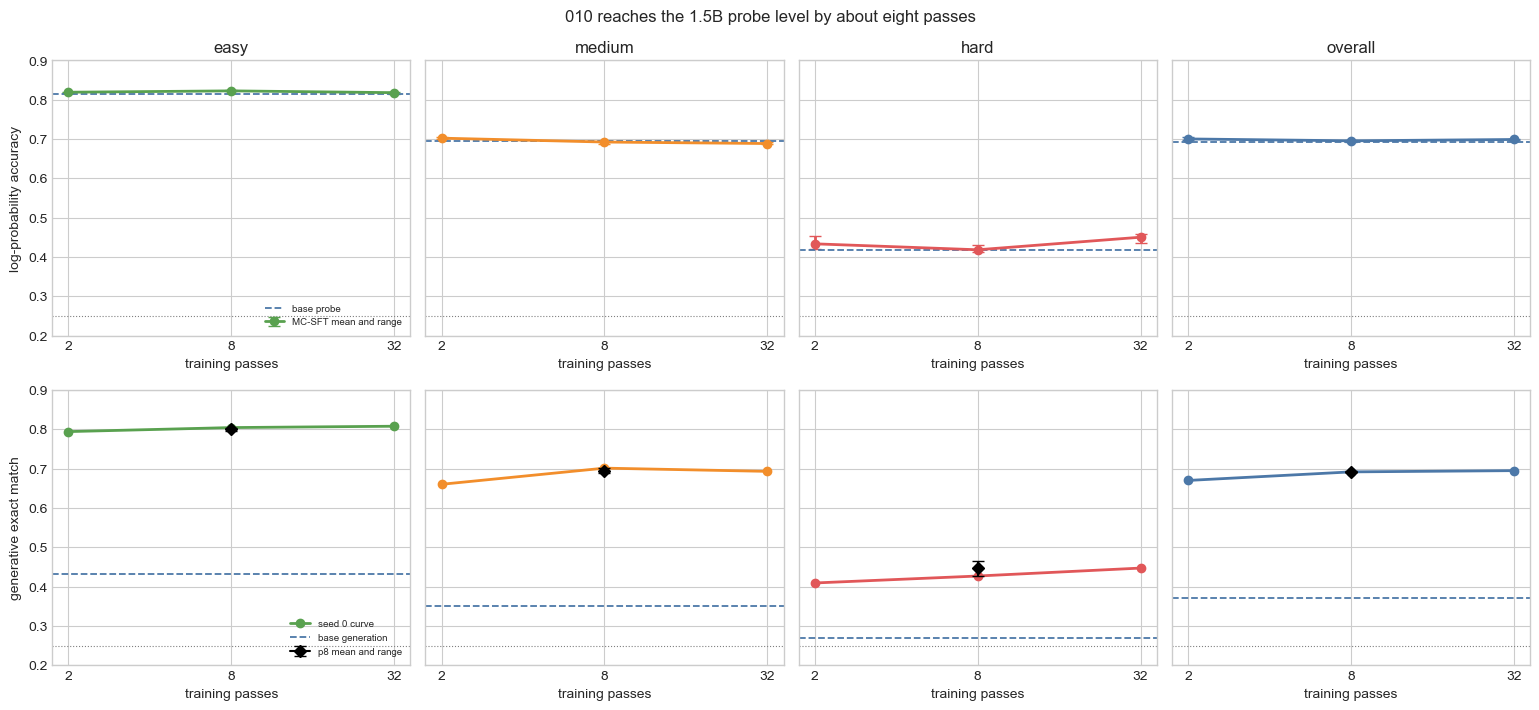

In [5]:
# compare the exposure curve with the pretrained generation and probe
fig, axes = plt.subplots(2, 4, figsize=(15.5, 7.2), sharey=True)
for col, group in enumerate(GROUPS):
    probe_part = probe_summary.query('group == @group').sort_values('passes')
    low = probe_part['mean'] - probe_part['min']
    high = probe_part['max'] - probe_part['mean']
    axes[0, col].errorbar(probe_part['passes'], probe_part['mean'], yerr=[low, high],
                           marker='o', capsize=4, lw=2, color=TIER_COLORS[group], label='MC-SFT mean and range')
    axes[0, col].axhline(accuracy(BASE_PROBE, group), color=COLORS['base'], ls='--', lw=1.3, label='base probe')
    seed0 = gen_df.query('group == @group and seed == 0').sort_values('passes')
    axes[1, col].plot(seed0['passes'], seed0['accuracy'], marker='o', lw=2,
                      color=TIER_COLORS[group], label='seed 0 curve')
    p8 = gen_summary.query("group == @group and exposure == 'p8'").iloc[0]
    axes[1, col].errorbar(8, p8['mean'], yerr=[[p8['mean'] - p8['min']], [p8['max'] - p8['mean']]],
                           marker='D', color='black', capsize=4, label='p8 mean and range')
    axes[1, col].axhline(accuracy(BASE_GEN, group), color=COLORS['base'], ls='--', lw=1.3, label='base generation')
    for row in (0, 1):
        axes[row, col].set_xscale('log', base=2)
        axes[row, col].set_xticks([2, 8, 32])
        axes[row, col].set_xticklabels(['2', '8', '32'])
        axes[row, col].set_ylim(0.2, 0.9)
        axes[row, col].axhline(0.25, color='grey', ls=':', lw=0.8)
        axes[row, col].set_xlabel('training passes')
    axes[0, col].set_title(group)
axes[0, 0].set_ylabel('log-probability accuracy')
axes[1, 0].set_ylabel('generative exact match')
axes[0, 0].legend(fontsize=7, loc='lower right')
axes[1, 0].legend(fontsize=7, loc='lower right')
fig.suptitle('010 reaches the 1.5B probe level by about eight passes')
fig.tight_layout()
save(fig, 'fig02_exposure_endpoints')
plt.show()

## 3. Complete 1.5B preparation and method comparison

The complete column now contains the pretrained base, GSM8K-SFT, base and warm-start GRPO, and base and warm-start MC-SFT. Means and ranges use every available generative seed, so the seed count remains visible in the table. The paired contrasts in the next section use seed 0 only.

In [6]:
# assemble the complete 1.5B endpoint matrix
METHODS = ['base', 'gsm_sft', 'base_grpo', 'warm_grpo', 'base_mc', 'warm_mc']
METHOD_LABELS = {
    'base': 'base', 'gsm_sft': 'GSM8K SFT', 'base_grpo': 'base GRPO',
    'warm_grpo': 'warm GRPO', 'base_mc': 'base MC-SFT', 'warm_mc': 'warm MC-SFT',
}
ENDPOINTS = {
    'base': {0: BASE_GEN},
    'gsm_sft': {seed: D9[seed]['sft_gen'] for seed in (0, 1)},
    'base_grpo': {0: D12['gen']},
    'warm_grpo': {seed: D9[seed]['grpo_gen'] for seed in (0, 1)},
    'base_mc': {seed: RUN10['p8'][seed]['gen'] for seed in SEEDS},
    'warm_mc': {seed: RUN11[seed]['gen'] for seed in SEEDS},
}
PROBES = {
    'base': {0: BASE_PROBE},
    'gsm_sft': {seed: D9[seed]['sft_probe'] for seed in (0, 1)},
    'base_grpo': {0: D12['probe']},
    'warm_grpo': {seed: D9[seed]['grpo_probe'] for seed in (0, 1)},
    'base_mc': {seed: RUN10['p8'][seed]['probe'] for seed in SEEDS},
    'warm_mc': {seed: RUN11[seed]['probe'] for seed in SEEDS},
}
endpoint_rows = []
for method in METHODS:
    for seed, rows in ENDPOINTS[method].items():
        for group in GROUPS:
            endpoint_rows.append({'method': method, 'seed': seed, 'group': group, 'accuracy': accuracy(rows, group)})
endpoint_df = pd.DataFrame(endpoint_rows)
endpoint_summary = endpoint_df.groupby(['method', 'group'])['accuracy'].agg(['mean', 'std', 'min', 'max', 'count']).reset_index()
display(endpoint_summary.set_index(['method', 'group']).loc[[(m, g) for m in METHODS for g in GROUPS]].round(4))

mean     std     min     max  count
method    group                                         
base      easy     0.4312     NaN  0.4312  0.4312      1
          medium   0.3498     NaN  0.3498  0.3498      1
          hard     0.2702     NaN  0.2702  0.2702      1
          overall  0.3710     NaN  0.3710  0.3710      1
gsm_sft   easy     0.6331  0.0072  0.6280  0.6382      2
          medium   0.5542  0.0313  0.5320  0.5764      2
          hard     0.2992  0.0054  0.2955  0.3030      2
          overall  0.5374  0.0146  0.5271  0.5478      2
base_grpo easy     0.7122     NaN  0.7122  0.7122      1
          medium   0.5829     NaN  0.5829  0.5829      1
          hard     0.4192     NaN  0.4192  0.4192      1
          overall  0.6088     NaN  0.6088  0.6088      1
warm_grpo easy     0.7884  0.0290  0.7679  0.8089      2
          medium   0.6125  0.0209  0.5977  0.6273      2
          hard     0.4217  0.0357  0.3965  0.4470      2
          overall  0.6545  0.0278  0.6348  0.6741      2
base_mc   easy     0.7998  0.0046  0.7952  0.8043      3
          medium   0.6940  0.0066  0.6880  0.7011      3
          hard     0.4478  0.0193  0.4268  0.4646      3
          overall  0.6916  0.0011  0.6906  0.6927      3
warm_mc   easy     0.8020  0.0079  0.7929  0.8066      3
          medium   0.6886  0.0068  0.6831  0.6962      3
          hard     0.4537  0.0077  0.4470  0.4621      3
          overall  0.6921  0.0038  0.6879  0.6953      3

saved fig03_complete_method_matrix


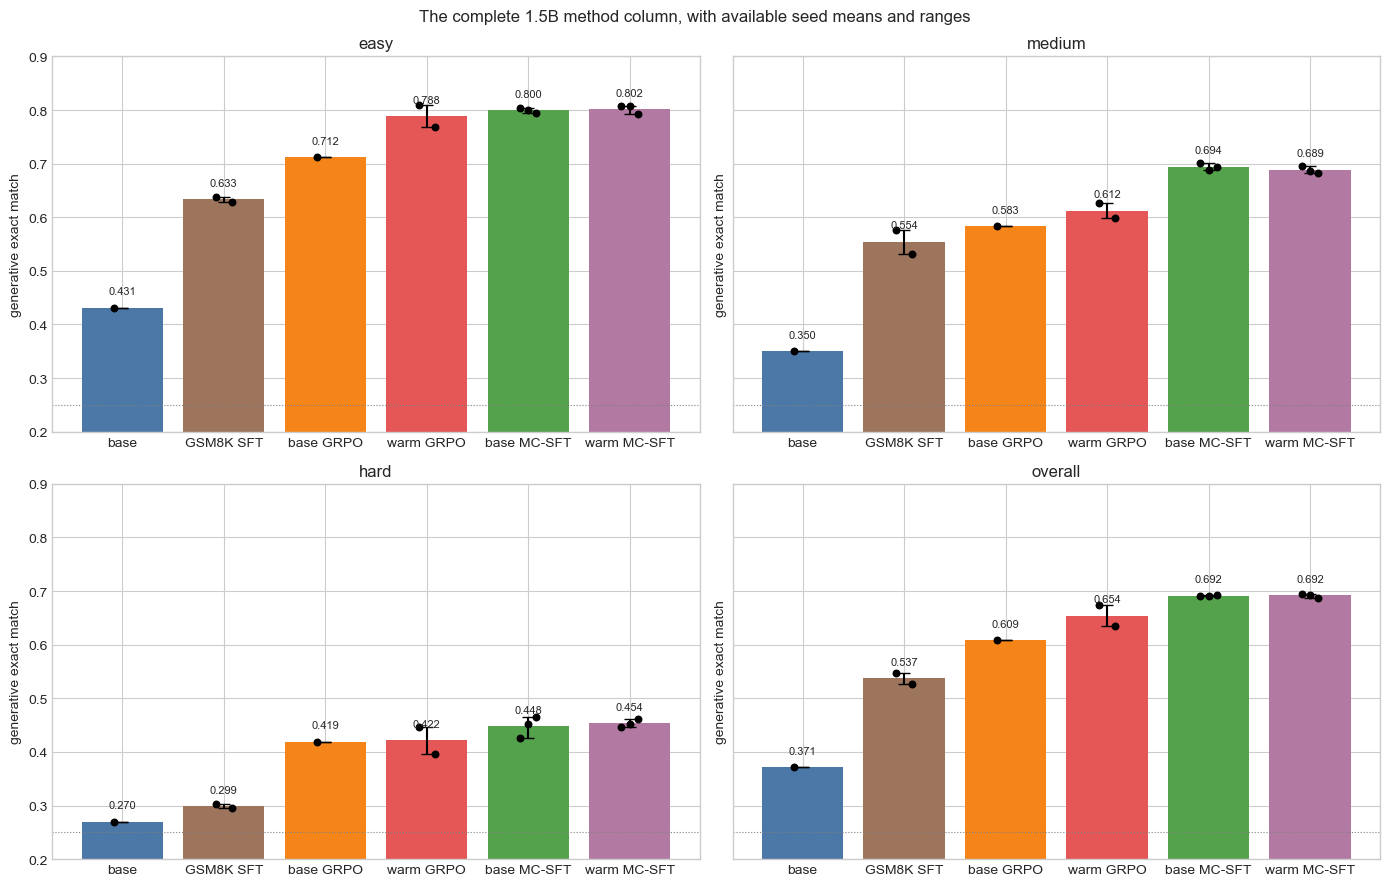

In [7]:
# plot every available 1.5B method with its full seed range
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
for ax, group in zip(axes.flat, GROUPS):
    part = endpoint_summary.query('group == @group').set_index('method').loc[METHODS]
    values = part['mean'].to_numpy()
    errors = [values - part['min'].to_numpy(), part['max'].to_numpy() - values]
    bars = ax.bar(np.arange(len(METHODS)), values, yerr=errors, capsize=4,
                  color=[COLORS[method] for method in METHODS])
    for position, method in enumerate(METHODS):
        seeds = endpoint_df.query('method == @method and group == @group')
        offsets = np.linspace(-0.08, 0.08, len(seeds))
        ax.scatter(position + offsets, seeds['accuracy'], s=22, color='black', zorder=3)
        ax.text(position, values[position] + 0.025, f'{values[position]:.3f}', ha='center', fontsize=8)
    ax.axhline(0.25, color='grey', ls=':', lw=0.8)
    ax.set_xticks(np.arange(len(METHODS)))
    ax.set_xticklabels([METHOD_LABELS[method] for method in METHODS])
    ax.set_ylim(0.2, 0.9)
    ax.set_title(group)
    ax.set_ylabel('generative exact match')
fig.suptitle('The complete 1.5B method column, with available seed means and ranges')
fig.tight_layout()
save(fig, 'fig03_complete_method_matrix')
plt.show()

In [8]:
# calculate matched seed-0 effects on the same 1,884 test items
def paired_bootstrap(rows_a, rows_b, group, seed, n_boot=10000, batch=500):
    rows_a, rows_b = align_pred_rows(rows_a, rows_b)
    if group != 'overall':
        rows_a = [row for row in rows_a if TIER_LOOKUP[row['subject']] == group]
        rows_b = [row for row in rows_b if TIER_LOOKUP[row['subject']] == group]
    a = np.asarray([bool(row['correct']) for row in rows_a], dtype=bool)
    b = np.asarray([bool(row['correct']) for row in rows_b], dtype=bool)
    diffs = b.astype(float) - a.astype(float)
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot)
    for start in range(0, n_boot, batch):
        size = min(batch, n_boot - start)
        indices = rng.integers(0, len(diffs), size=(size, len(diffs)))
        boot[start:start + size] = diffs[indices].mean(axis=1)
    a_only = int(np.sum(a & ~b))
    b_only = int(np.sum(~a & b))
    return {
        'delta': float(diffs.mean()), 'ci_lo': float(np.percentile(boot, 2.5)),
        'ci_hi': float(np.percentile(boot, 97.5)), 'a_only': a_only, 'b_only': b_only,
        'mcnemar_p': mcnemar_exact(a_only, b_only),
    }

CONTRASTS = {
    'base MC minus base GRPO': (D12['gen'], RUN10['p8'][0]['gen']),
    'warm MC minus warm GRPO': (D9[0]['grpo_gen'], RUN11[0]['gen']),
    'warm MC minus base MC': (RUN10['p8'][0]['gen'], RUN11[0]['gen']),
    'warm GRPO minus base GRPO': (D12['gen'], D9[0]['grpo_gen']),
}
contrast_rows = []
for contrast_index, (contrast, (rows_a, rows_b)) in enumerate(CONTRASTS.items()):
    for group_index, group in enumerate(GROUPS):
        result = paired_bootstrap(rows_a, rows_b, group, seed=1200 + contrast_index * 10 + group_index)
        contrast_rows.append({'contrast': contrast, 'group': group, **result})
contrast_df = pd.DataFrame(contrast_rows)
contrast_df['holm_p_tiers'] = np.nan
for contrast in CONTRASTS:
    mask = (contrast_df['contrast'] == contrast) & contrast_df['group'].isin(['easy', 'medium', 'hard'])
    contrast_df.loc[mask, 'holm_p_tiers'] = holm(contrast_df.loc[mask, 'mcnemar_p'].tolist())
display(contrast_df.set_index(['contrast', 'group']).round({
    'delta': 4, 'ci_lo': 4, 'ci_hi': 4, 'mcnemar_p': 8, 'holm_p_tiers': 8,
}))

delta   ci_lo   ci_hi  a_only  b_only  \
contrast                  group                                             
base MC minus base GRPO   easy     0.0922  0.0626  0.1229      54     135   
                          medium   0.1182  0.0821  0.1544      31     103   
                          hard     0.0076 -0.0556  0.0682      77      80   
                          overall  0.0828  0.0605  0.1051     162     318   
warm MC minus warm GRPO   easy    -0.0023 -0.0239  0.0193      47      45   
                          medium   0.0690  0.0378  0.1002      29      71   
                          hard     0.0000 -0.0581  0.0581      70      70   
                          overall  0.0212  0.0027  0.0403     146     186   
warm MC minus base MC     easy     0.0023 -0.0125  0.0171      22      24   
                          medium  -0.0049 -0.0246  0.0148      20      17   
                          hard     0.0202 -0.0101  0.0505      16      24   
                          overall  0.0037 -0.0080  0.0149      58      65   
warm GRPO minus base GRPO easy     0.0967  0.0683  0.1251      43     128   
                          medium   0.0443  0.0099  0.0788      44      71   
                          hard     0.0278 -0.0303  0.0859      64      75   
                          overall  0.0653  0.0435  0.0865     151     274   

                                   mcnemar_p  holm_p_tiers  
contrast                  group                             
base MC minus base GRPO   easy      0.000000  1.000000e-08  
                          medium    0.000000  0.000000e+00  
                          hard      0.873248  8.732481e-01  
                          overall   0.000000           NaN  
warm MC minus warm GRPO   easy      0.917041  1.000000e+00  
                          medium    0.000032  9.648000e-05  
                          hard      1.000000  1.000000e+00  
                          overall   0.032167           NaN  
warm MC minus base MC     easy      0.882996  1.000000e+00  
                          medium    0.742829  1.000000e+00  
                          hard      0.268187  8.045617e-01  
                          overall   0.588688           NaN  
warm GRPO minus base GRPO easy      0.000000  0.000000e+00  
                          medium    0.014965  2.992934e-02  
                          hard      0.396415  3.964151e-01  
                          overall   0.000000           NaN

saved fig04_paired_method_effects


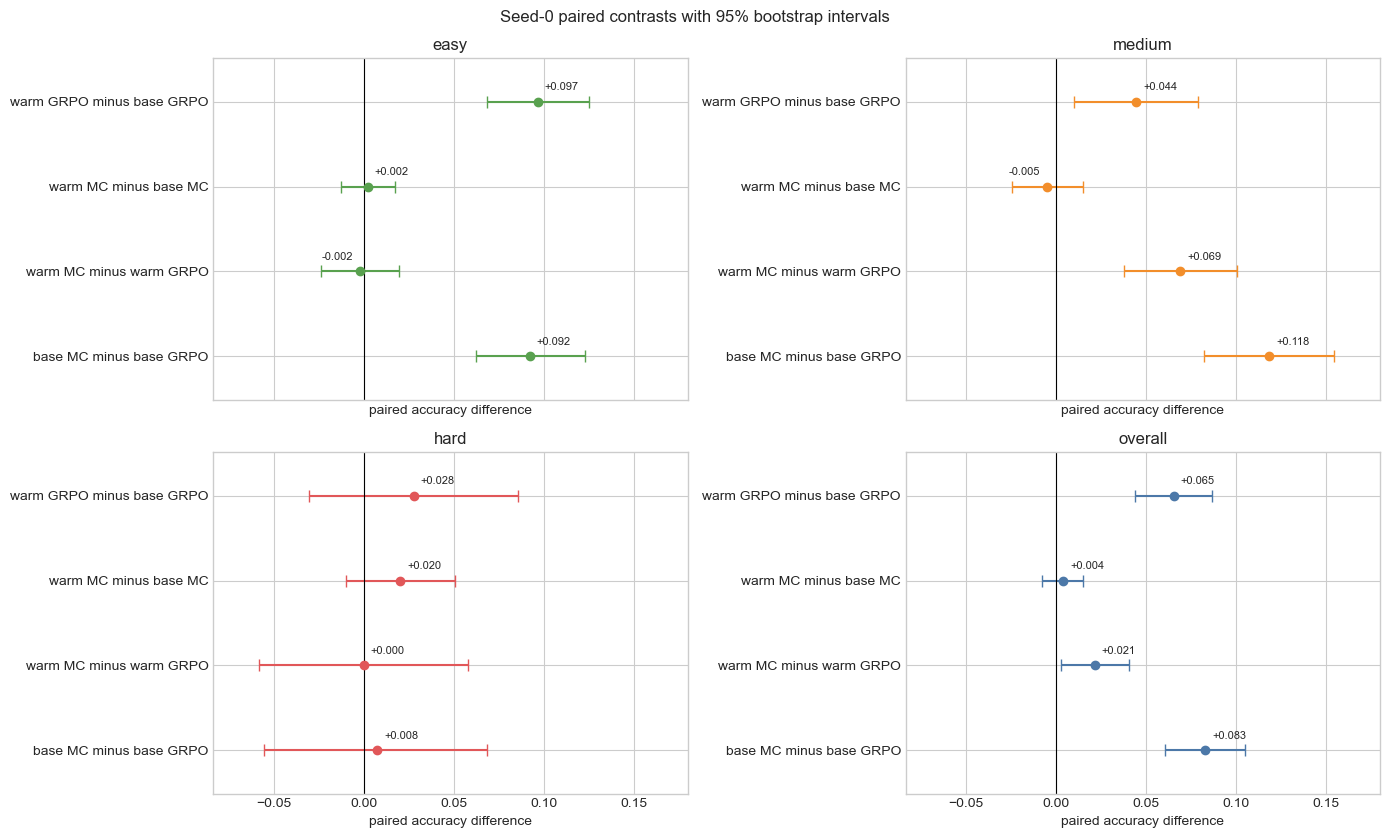

In [9]:
# plot the paired effects separately for every validated tier
fig, axes = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
contrast_order = list(CONTRASTS)
for ax, group in zip(axes.flat, GROUPS):
    part = contrast_df.query('group == @group').set_index('contrast').loc[contrast_order]
    y = np.arange(len(contrast_order))
    values = part['delta'].to_numpy()
    errors = [values - part['ci_lo'].to_numpy(), part['ci_hi'].to_numpy() - values]
    ax.errorbar(values, y, xerr=errors, fmt='o', capsize=4, color=TIER_COLORS[group])
    ax.axvline(0, color='black', lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(contrast_order)
    ax.set_title(group)
    ax.set_xlabel('paired accuracy difference')
    ax.margins(x=0.12, y=0.17)
    for position, value in zip(y, values):
        ax.annotate(f'{value:+.3f}', (value, position), xytext=(5 if value >= 0 else -5, 7),
                    textcoords='offset points', ha='left' if value >= 0 else 'right',
                    va='bottom', fontsize=8)
fig.suptitle('Seed-0 paired contrasts with 95% bootstrap intervals')
fig.tight_layout()
save(fig, 'fig04_paired_method_effects')
plt.show()

## 4. Why the warm start changes GRPO more than MC-SFT

Experiment 012 uses the same GRPO protocol as 009 but removes the GSM8K-SFT preparation. The trajectory comparison checks reward learning, format discovery, response length and clipping before looking at the final evaluation diagnostics.

saved fig05_grpo_trajectory_comparison


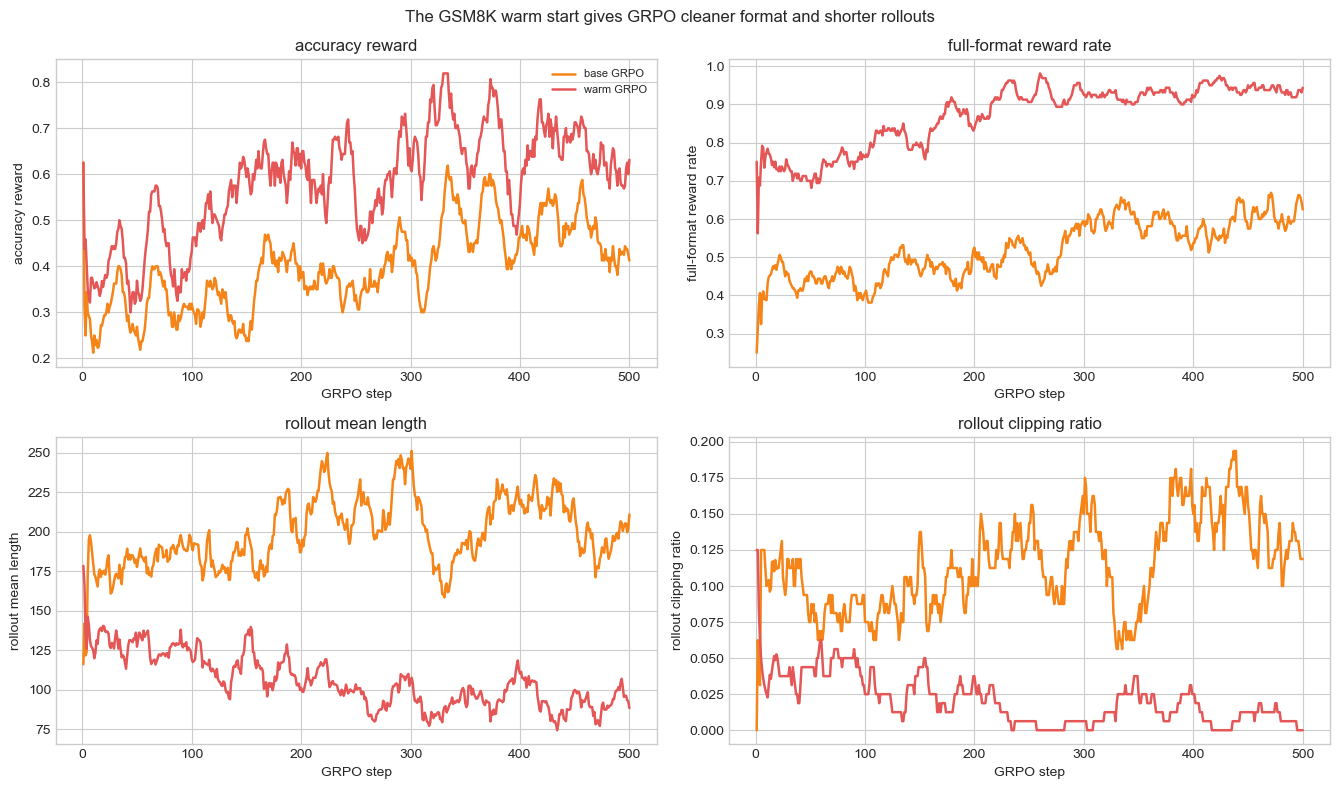

accuracy reward  format rate  mean length  clipped ratio  \
condition window                                                               
base GRPO first 50           0.2950        0.445     175.8875         0.0975   
          last 50            0.4475        0.630     193.0800         0.1175   
warm GRPO first 50           0.3950        0.730     129.0000         0.0375   
          last 50            0.6350        0.935      87.4825         0.0075   

                    zero-std groups  
condition window                     
base GRPO first 50             0.00  
          last 50              0.00  
warm GRPO first 50             0.02  
          last 50              0.30

In [10]:
# compare the warm-start and base-start GRPO trajectories
TRAJECTORIES = {'base GRPO': D12['trainlog'], 'warm GRPO': D9[0]['trainlog']}
TRAJ_COLORS = {'base GRPO': COLORS['base_grpo'], 'warm GRPO': COLORS['warm_grpo']}
trajectory_specs = [
    ('rewards/accuracy_reward/mean', 'accuracy reward', 1.0),
    ('rewards/format_reward/mean', 'full-format reward rate', 0.2),
    ('completions/mean_length', 'rollout mean length', 1.0),
    ('completions/clipped_ratio', 'rollout clipping ratio', 1.0),
]
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8))
for ax, (key, label, divisor) in zip(axes.flat, trajectory_specs):
    for condition, log in TRAJECTORIES.items():
        rows = [row for row in log if key in row and 'step' in row]
        frame = pd.DataFrame(rows)
        values = (frame[key] / divisor).rolling(20, min_periods=1).mean()
        ax.plot(frame['step'], values, lw=1.8, color=TRAJ_COLORS[condition], label=condition)
    ax.set_title(label)
    ax.set_xlabel('GRPO step')
    ax.set_ylabel(label)
axes[0, 0].legend(fontsize=8)
fig.suptitle('The GSM8K warm start gives GRPO cleaner format and shorter rollouts')
fig.tight_layout()
save(fig, 'fig05_grpo_trajectory_comparison')
plt.show()

trajectory_rows = []
for condition, log in TRAJECTORIES.items():
    rows = [row for row in log if 'reward' in row and 'step' in row]
    for window_name, selected in [('first 50', rows[:50]), ('last 50', rows[-50:])]:
        trajectory_rows.append({
            'condition': condition, 'window': window_name,
            'accuracy reward': np.mean([row['rewards/accuracy_reward/mean'] for row in selected]),
            'format rate': np.mean([row['rewards/format_reward/mean'] / 0.2 for row in selected]),
            'mean length': np.mean([row['completions/mean_length'] for row in selected]),
            'clipped ratio': np.mean([row['completions/clipped_ratio'] for row in selected]),
            'zero-std groups': np.mean([row['frac_reward_zero_std'] for row in selected]),
        })
display(pd.DataFrame(trajectory_rows).set_index(['condition', 'window']).round(4))

format compliance                 extraction failure          \
                       mean     min     max               mean     min   
method                                                                   
base                 0.6492  0.6492  0.6492             0.1667  0.1667   
gsm_sft              0.8978  0.8609  0.9347             0.0499  0.0483   
base_grpo            0.7611  0.7611  0.7611             0.0924  0.0924   
warm_grpo            0.9594  0.9544  0.9644             0.0337  0.0255   
base_mc              0.9988  0.9968  1.0000             0.0000  0.0000   
warm_mc              1.0000  1.0000  1.0000             0.0000  0.0000   

                  mean response length                      
              max                 mean       min       max  
method                                                      
base       0.1667             104.2574  104.2574  104.2574  
gsm_sft    0.0515             107.8697  107.3917  108.3477  
base_grpo  0.0924             148.3015  148.3015  148.3015  
warm_grpo  0.0419              88.2216   82.8259   93.6173  
base_mc    0.0000              16.4467   16.1614   16.7718  
warm_mc    0.0000              16.0004   16.0000   16.0011

saved fig06_output_diagnostics


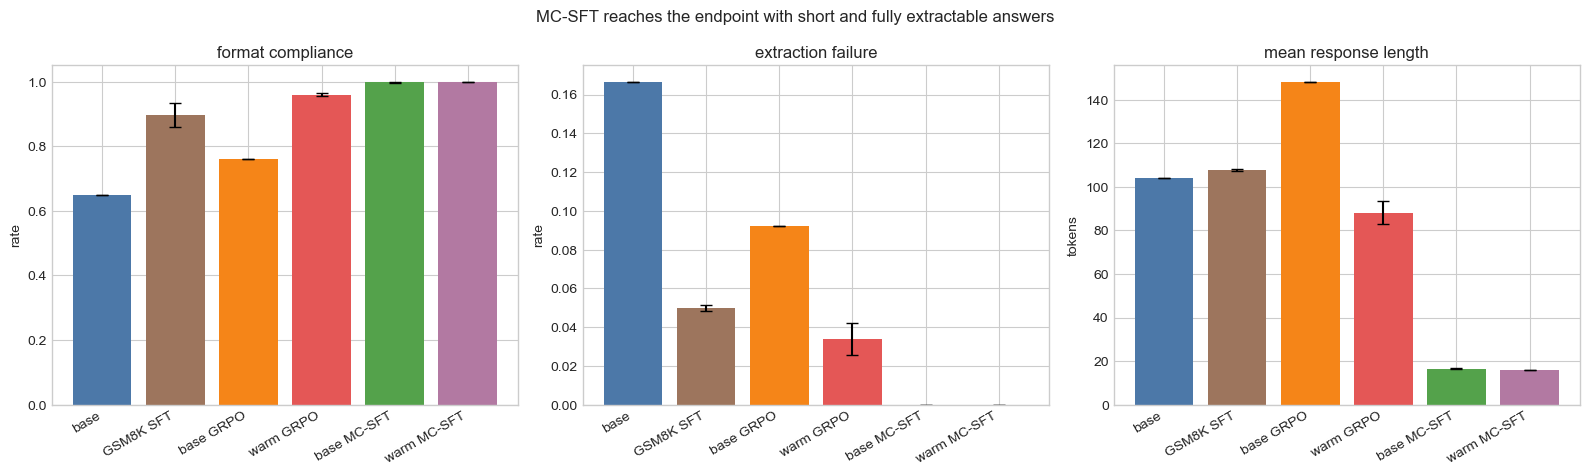

In [11]:
# compare final output behaviour for all six 1.5B methods
diagnostic_rows = []
for method in METHODS:
    for seed, rows in ENDPOINTS[method].items():
        diagnostic_rows.append({'method': method, 'seed': seed, **diagnosis(rows)})
diagnostic_df = pd.DataFrame(diagnostic_rows)
diagnostic_summary = diagnostic_df.groupby('method').agg({
    'format compliance': ['mean', 'min', 'max'],
    'extraction failure': ['mean', 'min', 'max'],
    'mean response length': ['mean', 'min', 'max'],
})
display(diagnostic_summary.loc[METHODS].round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, metric in zip(axes, ['format compliance', 'extraction failure', 'mean response length']):
    part = diagnostic_df.groupby('method')[metric].agg(['mean', 'min', 'max']).loc[METHODS]
    values = part['mean'].to_numpy()
    errors = [values - part['min'].to_numpy(), part['max'].to_numpy() - values]
    ax.bar(np.arange(len(METHODS)), values, yerr=errors, capsize=4,
           color=[COLORS[method] for method in METHODS])
    ax.set_xticks(np.arange(len(METHODS)))
    ax.set_xticklabels([METHOD_LABELS[method] for method in METHODS], rotation=30, ha='right')
    ax.set_title(metric)
    ax.set_ylabel('tokens' if metric == 'mean response length' else 'rate')
fig.suptitle('MC-SFT reaches the endpoint with short and fully extractable answers')
fig.tight_layout()
save(fig, 'fig06_output_diagnostics')
plt.show()

saved fig07_subject_accuracy_matrix


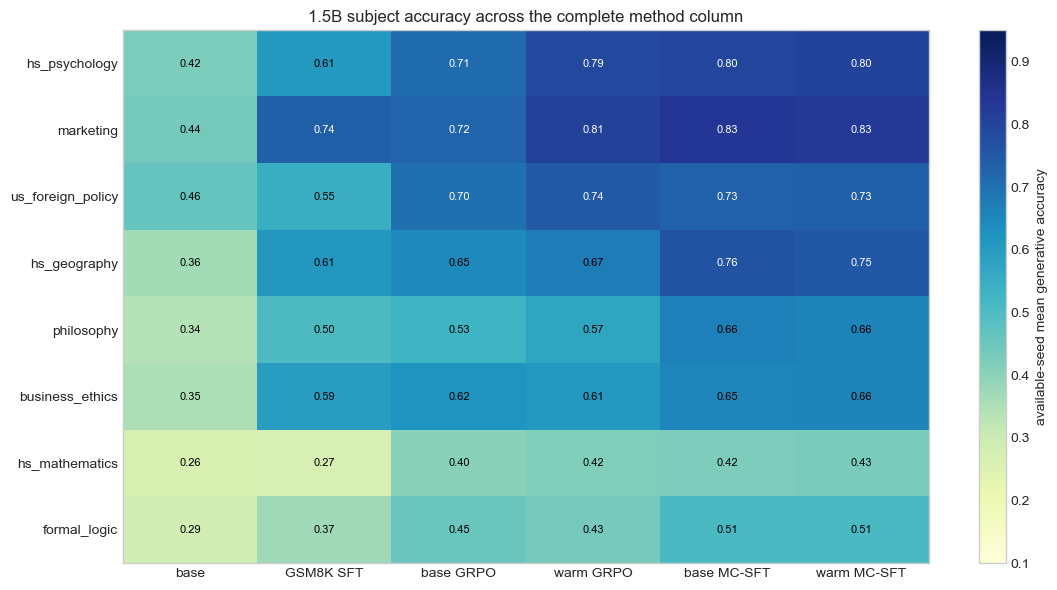

In [12]:
# plot the complete method matrix by subject without heatmap seams
matrix = []
for method in METHODS:
    seed_values = []
    for rows in ENDPOINTS[method].values():
        values = subject_accuracy(rows)
        seed_values.append([values[subject] for subject in SUBJECTS])
    matrix.append(np.mean(seed_values, axis=0))
matrix = np.asarray(matrix).T

fig, ax = plt.subplots(figsize=(11.5, 6))
image = ax.imshow(matrix, aspect='auto', vmin=0.1, vmax=0.95, cmap='YlGnBu', interpolation='nearest')
ax.set_xticks(np.arange(len(METHODS)))
ax.set_xticklabels([METHOD_LABELS[method] for method in METHODS])
ax.set_yticks(np.arange(len(SUBJECTS)))
ax.set_yticklabels(SHORT_SUBJECTS)
for row_index in range(matrix.shape[0]):
    for column_index in range(matrix.shape[1]):
        value = matrix[row_index, column_index]
        ax.text(column_index, row_index, f'{value:.2f}', ha='center', va='center',
                color=heatmap_text_color(image, value), fontsize=8)
ax.grid(False)
ax.set_title('1.5B subject accuracy across the complete method column')
fig.colorbar(image, ax=ax, label='available-seed mean generative accuracy')
fig.tight_layout()
save(fig, 'fig07_subject_accuracy_matrix')
plt.show()

## 5. Base-GRPO scale pattern and compute

Experiments 005, 012 and 004 give the seed-0 base-to-GRPO comparison at 0.5B, 1.5B and 3B. This is a descriptive cross-scale extension. The 1.5B run is on A100 80GB; exact devices remain in the table and runtime is not treated as hardware-normalised.

,base,base probe,base GRPO,format compliance,extraction failure,mean response length,GPU,easy,medium,hard,expression gap closed
scale,,,,,,,,,,,
0.5B,0.1852,0.5669,0.3992,0.0175,0.0823,269.2792,NVIDIA A100-SXM4-40GB,0.4881,0.3645,0.2551,0.5605
1.5B,0.3710,0.6921,0.6088,0.7611,0.0924,148.3015,NVIDIA A100-SXM4-80GB,0.7122,0.5829,0.4192,0.7405
3B,0.5961,0.7389,0.6768,0.9374,0.0494,119.5042,NVIDIA A100-SXM4-80GB,0.7770,0.6190,0.5429,0.5651


saved fig08_base_grpo_scale_pattern


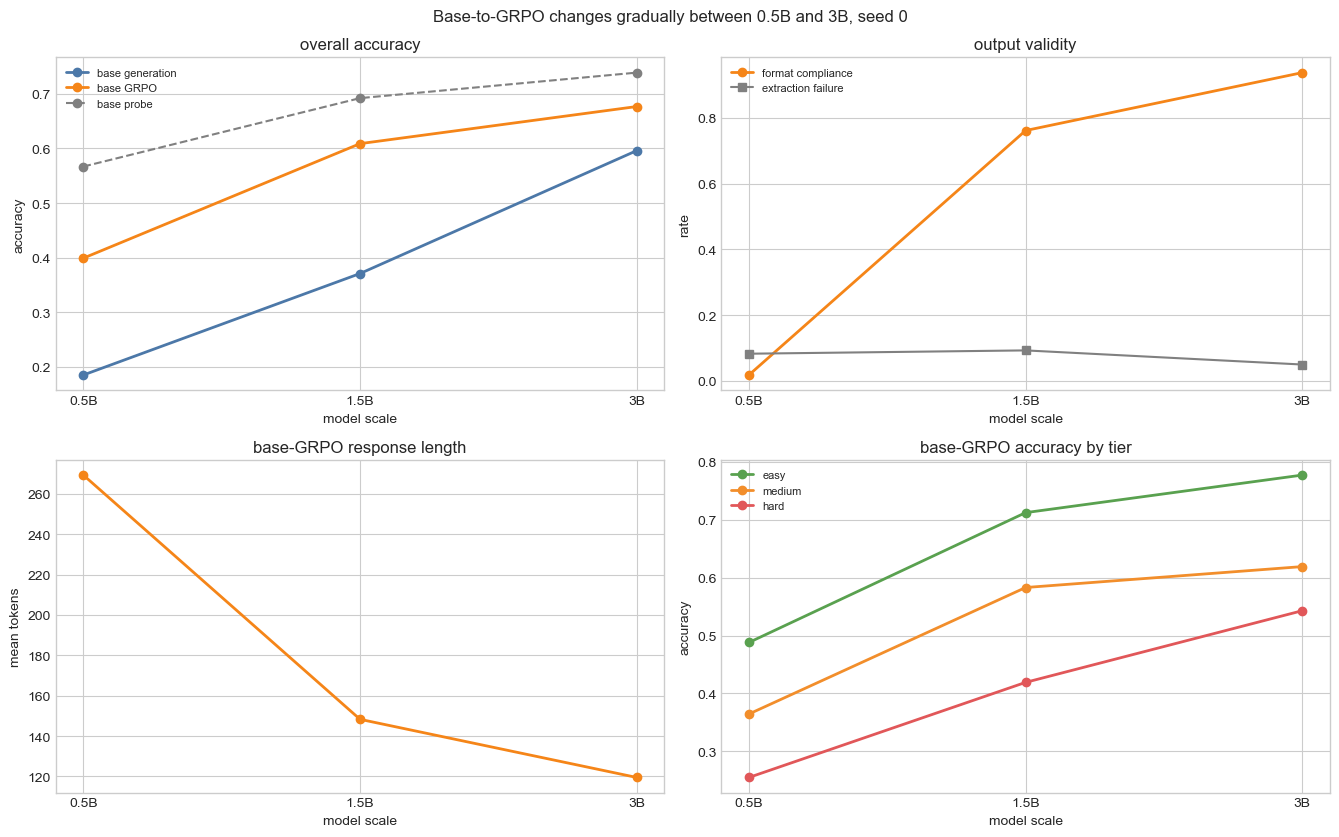

In [13]:
# compare base-to-GRPO behaviour across the three completed Qwen scales
scale_rows = []
for scale, data in BASE_GRPO.items():
    row = {
        'scale': scale, 'base': accuracy(data['base']), 'base probe': accuracy(data['base_probe']),
        'base GRPO': accuracy(data['grpo']), 'format compliance': diagnosis(data['grpo'])['format compliance'],
        'extraction failure': diagnosis(data['grpo'])['extraction failure'],
        'mean response length': diagnosis(data['grpo'])['mean response length'],
        'GPU': data['manifest']['gpu']['device'],
    }
    for tier in ['easy', 'medium', 'hard']:
        row[tier] = accuracy(data['grpo'], tier)
    gap = row['base probe'] - row['base']
    row['expression gap closed'] = (row['base GRPO'] - row['base']) / gap if gap > 0 else np.nan
    scale_rows.append(row)
scale_tbl = pd.DataFrame(scale_rows).set_index('scale').loc[['0.5B', '1.5B', '3B']]
display(scale_tbl.round(4))

x = np.arange(len(scale_tbl))
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.5))
axes[0, 0].plot(x, scale_tbl['base'], marker='o', lw=2, color=COLORS['base'], label='base generation')
axes[0, 0].plot(x, scale_tbl['base GRPO'], marker='o', lw=2, color=COLORS['base_grpo'], label='base GRPO')
axes[0, 0].plot(x, scale_tbl['base probe'], marker='o', lw=1.5, ls='--', color='grey', label='base probe')
axes[0, 0].set_title('overall accuracy')
axes[0, 0].set_ylabel('accuracy')
axes[0, 0].legend(fontsize=8)
axes[0, 1].plot(x, scale_tbl['format compliance'], marker='o', lw=2, color=COLORS['base_grpo'], label='format compliance')
axes[0, 1].plot(x, scale_tbl['extraction failure'], marker='s', lw=1.5, color='grey', label='extraction failure')
axes[0, 1].set_title('output validity')
axes[0, 1].set_ylabel('rate')
axes[0, 1].legend(fontsize=8)
axes[1, 0].plot(x, scale_tbl['mean response length'], marker='o', lw=2, color=COLORS['base_grpo'])
axes[1, 0].set_title('base-GRPO response length')
axes[1, 0].set_ylabel('mean tokens')
for tier in ['easy', 'medium', 'hard']:
    axes[1, 1].plot(x, scale_tbl[tier], marker='o', lw=2, color=TIER_COLORS[tier], label=tier)
axes[1, 1].set_title('base-GRPO accuracy by tier')
axes[1, 1].set_ylabel('accuracy')
axes[1, 1].legend(fontsize=8)
for ax in axes.flat:
    ax.set_xticks(x)
    ax.set_xticklabels(scale_tbl.index)
    ax.set_xlabel('model scale')
fig.suptitle('Base-to-GRPO changes gradually between 0.5B and 3B, seed 0')
fig.tight_layout()
save(fig, 'fig08_base_grpo_scale_pattern')
plt.show()

,accuracy,training hours
method,,
base MC-SFT,0.6916,0.0466
warm MC-SFT,0.6953,0.2616
base GRPO,0.6088,5.0385
warm GRPO,0.6741,3.2771


saved fig09_accuracy_vs_training_time


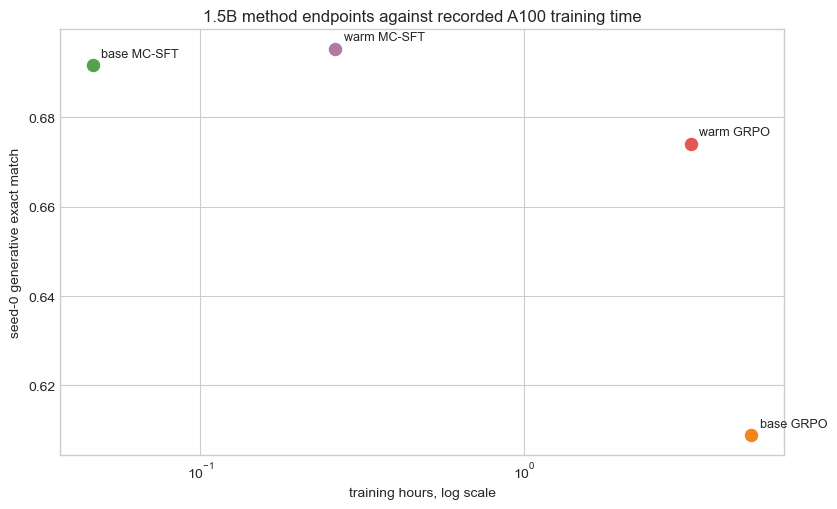

In [14]:
# compare seed-0 accuracy with the full training time of each 1.5B route
compute_rows = [
    {'method': 'base MC-SFT', 'accuracy': accuracy(RUN10['p8'][0]['gen']),
     'training hours': RUN10['p8'][0]['manifest']['timings_sec']['sft_train'] / 3600},
    {'method': 'warm MC-SFT', 'accuracy': accuracy(RUN11[0]['gen']),
     'training hours': (D9[0]['manifest']['timings_sec']['sft_train'] + RUN11[0]['manifest']['timings_sec']['sft_train']) / 3600},
    {'method': 'base GRPO', 'accuracy': accuracy(D12['gen']),
     'training hours': D12['manifest']['timings_sec']['grpo_train'] / 3600},
    {'method': 'warm GRPO', 'accuracy': accuracy(D9[0]['grpo_gen']),
     'training hours': (D9[0]['manifest']['timings_sec']['sft_train'] + D9[0]['manifest']['timings_sec']['grpo_train']) / 3600},
]
compute_tbl = pd.DataFrame(compute_rows)
display(compute_tbl.set_index('method').round(4))

fig, ax = plt.subplots(figsize=(8.5, 5.2))
method_color = {'base MC-SFT': COLORS['base_mc'], 'warm MC-SFT': COLORS['warm_mc'],
                'base GRPO': COLORS['base_grpo'], 'warm GRPO': COLORS['warm_grpo']}
for _, row in compute_tbl.iterrows():
    ax.scatter(row['training hours'], row['accuracy'], s=75, color=method_color[row['method']])
    ax.annotate(row['method'], (row['training hours'], row['accuracy']),
                xytext=(6, 6), textcoords='offset points', fontsize=9)
ax.set_xscale('log')
ax.set_xlabel('training hours, log scale')
ax.set_ylabel('seed-0 generative exact match')
ax.set_title('1.5B method endpoints against recorded A100 training time')
fig.tight_layout()
save(fig, 'fig09_accuracy_vs_training_time')
plt.show()

## 6. Exact result tables

In [15]:
# keep the exact values used by the figures in compact tables
overall_exposure = gen_summary.query("group == 'overall'").set_index('exposure').loc[EXPOSURES]
overall_methods = endpoint_summary.query("group == 'overall'").set_index('method').loc[METHODS]
overall_contrasts = contrast_df.query("group == 'overall'").set_index('contrast').loc[list(CONTRASTS)]
print('010 overall generative exposure summary')
display(overall_exposure.round(4))
print('complete 1.5B overall endpoint summary')
display(overall_methods.round(4))
print('matched seed-0 overall contrasts')
display(overall_contrasts[['delta', 'ci_lo', 'ci_hi', 'a_only', 'b_only', 'mcnemar_p']].round(6))
print('subject matrix values')
display(pd.DataFrame(matrix, index=SUBJECTS, columns=METHODS).round(4))

010 overall generative exposure summary


,passes,group,mean,std,min,max,count
exposure,,,,,,,
p2,2,overall,0.6699,NaN,0.6699,0.6699,1
p8,8,overall,0.6916,0.0011,0.6906,0.6927,3
p32,32,overall,0.6948,NaN,0.6948,0.6948,1


complete 1.5B overall endpoint summary


,group,mean,std,min,max,count
method,,,,,,
base,overall,0.3710,NaN,0.3710,0.3710,1
gsm_sft,overall,0.5374,0.0146,0.5271,0.5478,2
base_grpo,overall,0.6088,NaN,0.6088,0.6088,1
warm_grpo,overall,0.6545,0.0278,0.6348,0.6741,2
base_mc,overall,0.6916,0.0011,0.6906,0.6927,3
warm_mc,overall,0.6921,0.0038,0.6879,0.6953,3


matched seed-0 overall contrasts


,delta,ci_lo,ci_hi,a_only,b_only,mcnemar_p
contrast,,,,,,
base MC minus base GRPO,0.082803,0.060510,0.105096,162,318,0.000000
warm MC minus warm GRPO,0.021231,0.002654,0.040340,146,186,0.032167
warm MC minus base MC,0.003715,-0.007962,0.014862,58,65,0.588688
warm GRPO minus base GRPO,0.065287,0.043524,0.086518,151,274,0.000000


subject matrix values


,base,gsm_sft,base_grpo,warm_grpo,base_mc,warm_mc
high_school_psychology,0.4239,0.6055,0.7101,0.7881,0.7976,0.8037
marketing,0.4359,0.7350,0.7222,0.8077,0.8348,0.8276
us_foreign_policy,0.4600,0.5450,0.7000,0.7450,0.7300,0.7333
high_school_geography,0.3636,0.6136,0.6465,0.6742,0.7609,0.7525
philosophy,0.3408,0.5032,0.5305,0.5740,0.6645,0.6581
business_ethics,0.3500,0.5950,0.6200,0.6100,0.6533,0.6567
high_school_mathematics,0.2630,0.2667,0.4037,0.4167,0.4210,0.4284
formal_logic,0.2857,0.3690,0.4524,0.4325,0.5053,0.5079


## Cross-referenced conclusion

1. Experiment 010 gives the same main result as 007 at the middle scale. Base-start MC-SFT rises from 67.0% after 2 passes to a three-seed mean of 69.2% after 8 passes. The 8-pass range is only 69.1% to 69.3%, and the seed-0 32-pass result is 69.5%. Most of the useful change is therefore already present by 8 passes. The probe stays close to the pretrained 69.2% level, while generation catches up to it.

2. Experiment 011 confirms the 008 warm-start result at 1.5B. Warm MC-SFT averages 69.2%, only 0.05 points above base-start MC-SFT. In the matched seed-0 comparison the change is +0.4 points with an interval crossing zero. GSM8K-SFT is therefore not needed for MC-SFT in this setup.

3. MC-SFT is the stronger overall MMLU method at 1.5B. Base MC-SFT beats base GRPO by 8.3 points at seed 0. Warm MC-SFT beats warm GRPO by 2.1 points overall, mainly from the medium tier. The hard tier is a tie after the warm start, 44.7% for both methods. This means the clear 3B hard-tier GRPO advantage from 007 and 008 has not appeared at 1.5B.

4. Experiment 012 improves substantially over the pretrained base, 37.1% to 60.9%, so base-to-GRPO does work at 1.5B. It is still below warm GRPO at 67.4% and below MC-SFT around 69.2%. The warm start adds 6.5 points to GRPO at matched seed 0, but almost nothing to MC-SFT.

5. The no-warm-start format result looks gradual rather than a sharp threshold. Base-GRPO format compliance moves from 1.8% at 0.5B to 76.1% at 1.5B and 93.7% at 3B. The 1.5B model avoids the full 0.5B collapse, but its responses are still longer and less reliable than warm GRPO. These base-GRPO comparisons were a prospective extension and used seed 0 only, so they cannot establish a general scale threshold for following the requested format.

Overall, GRPO clearly improves models below 7B in this protocol, including without SFT at 1.5B. The new controls also strengthen the more careful conclusion: most of the endpoint gain can be reproduced more cheaply by supervised answer-key training, while the value of GRPO depends on preparation, scale and tier.